# 3.3 Feature Engineering: drop-column ablation #
XGBoost is refitted without each feature (or group of features) on the three validation windows of the training period, and the increase in validation MAE is compared with the model on every feature. A feature is worth keeping when removing it makes the MAE worse; the 95 % interval comes from resampling whole validation days.

| Report | Output |
|---|---|
| Figure `fig:ablation-study` | `results/figures/feature_ablation.png` |
| Per-feature numbers (not in the report) | `results/tables/feature_ablation.tex` |

**Inputs:** `data/dataset.csv`. **Run time:** about 1.5 minutes (57 XGBoost fits).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parents[1] / "src"))   #helper modules shared by the notebooks
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import xgboost as xgb
from forecast_checks import MakeTrainingData, paired_bootstrap

In [2]:
FIGURES, TABLES = Path("results/figures"), Path("results/tables")
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
#Smaller than the grid-search best in 03_xgboost.ipynb (1000 trees, learning rate 0.025), so the 57 refits run
#in minutes; the same settings as 01_missing_data.ipynb
PARAMS = dict(enable_categorical=True, tree_method="hist", random_state=42,
              n_estimators=500, learning_rate=0.05, max_depth=5)
LABELS = {"location": "Location", "temperature": "Temperature", "hour": "Hour", "weekday": "Weekday",
          "weekend": "Weekend", "holiday": "Holiday", "consumption_6days_ago": "Lag 6 d",
          "consumption_7days_ago": "Lag 7 d", "consumption_14days_ago": "Lag 14 d",
          "min_consumption_last_available_day": "Min of last available day",
          "max_consumption_last_available_day": "Max of last available day",
          "precipitation": "Precipitation", "rain": "Rain", "snowfall": "Snowfall",
          "wind_speed_10m": "Wind speed", "wind_direction_10m": "Wind direction"}
#weekend is weekday >= 5, so removing one alone can hide what the pair adds
GROUPS = {"Weekday + weekend": ["weekday", "weekend"]}
BLUE, GREY, ORANGE = "#4C72B0", "#B8B8B8", "#DD8452"   #blue and orange from the report palette (seaborn "deep")
INK, MUTED = "#2b2a27", "#6b6a66"

## Data and validation windows ##
The same three 2-week windows as the model notebooks, each fitted up to 6 days before it.

In [3]:
trainer = MakeTrainingData()
X = trainer.get_train_test()["train"]["feature"]
y, dates = trainer.df.loc[X.index, "consumption"], trainer.df.loc[X.index, "date"]
windows = MakeTrainingData.validation_windows(dates)
val_index = pd.Index(np.concatenate([val for _, val in windows]))
ablations = {"All features": []} | {LABELS[c]: [c] for c in X.columns} | GROUPS

## Refit without each feature ##

In [4]:
def validation_forecast(dropped: list[str]) -> pd.Series:
    """Forecasts on every validation window, each fitted up to 6 days before it, without the dropped columns."""
    cols = [c for c in X.columns if c not in dropped]
    parts = [pd.Series(xgb.XGBRegressor(**PARAMS).fit(X.loc[fit, cols], y[fit]).predict(X.loc[val, cols]), index=val)
             for fit, val in windows]
    return pd.concat(parts).loc[val_index]


forecasts = {}
for name, dropped in ablations.items():
    forecasts[name] = validation_forecast(dropped)
    print(f"fitted without {name}")

fitted without All features


fitted without Location


fitted without Temperature


fitted without Hour


fitted without Weekday


...

fitted without Rain


fitted without Snowfall


fitted without Wind speed


fitted without Wind direction


fitted without Weekday + weekend


## Change in validation MAE when a feature is removed ##
Positive = the model is worse without it. The 95 % interval comes from `paired_bootstrap` over whole validation days.

In [5]:
actual, full = y[val_index], forecasts.pop("All features")
full_mae = (full - actual).abs().mean()
one_group = pd.Series("all", index=val_index)
rows = {name: paired_bootstrap(actual, pred, full, dates[val_index], one_group).iloc[0]
        for name, pred in forecasts.items()}
result = pd.DataFrame(rows).T.astype({"mae_difference": float, "ci_low": float, "ci_high": float})
result["pct"] = 100 * result["mae_difference"] / full_mae
result = result.sort_values("mae_difference")
pct_low, pct_high = 100 * result["ci_low"] / full_mae, 100 * result["ci_high"] / full_mae
print(f"Validation MAE with every feature: {full_mae:.3f} MW")
result.round(4)

Validation MAE with every feature: 0.648 MW


,mae_difference,ci_low,ci_high,significant,pct
Min of last available day,-0.0227,-0.0329,-0.0116,True,-3.5094
Wind direction,-0.0146,-0.0295,-0.0008,True,-2.2562
Wind speed,-0.0135,-0.0269,-0.0009,True,-2.0861
Precipitation,-0.0043,-0.0097,0.0016,False,-0.6626
Snowfall,-0.0007,-0.0041,0.0029,False,-0.1016
Weekend,0.0000,0.0000,0.0000,False,0.0000
Max of last available day,0.0014,-0.0216,0.0239,False,0.2189
Weekday,0.0036,-0.0042,0.0110,False,0.5535
Weekday + weekend,0.0058,-0.0073,0.0188,False,0.8919
Holiday,0.0070,0.0013,0.0131,True,1.0876


## Figure `fig:ablation-study` ##

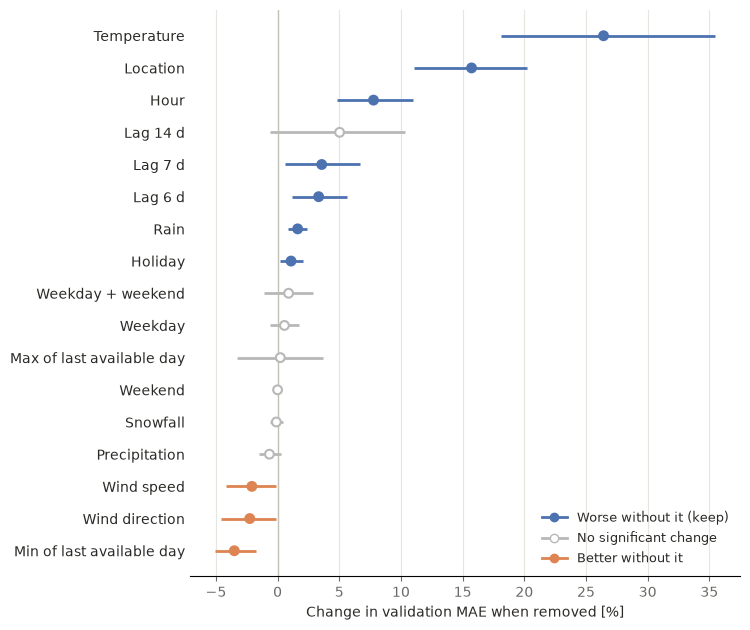

In [6]:
#Blue: removing it makes the forecast worse (keep); orange: removing it helps; grey and hollow: no significant change
colour = np.where(result["ci_low"] > 0, BLUE, np.where(result["ci_high"] < 0, ORANGE, GREY))
fill = np.where(colour == GREY, "white", colour)
pos = np.arange(len(result))
fig, ax = plt.subplots(figsize=(7.6, 6.4))
ax.axvline(0, color="#c3c2b7", linewidth=1, zorder=1)
ax.hlines(pos, pct_low, pct_high, color=colour, linewidth=2, zorder=2)
ax.scatter(result["pct"], pos, s=40, facecolor=fill, edgecolor=colour, linewidth=1.5, zorder=3)
ax.set_yticks(pos, result.index)
ax.set_xlabel("Change in validation MAE when removed [%]", color=INK)
ax.grid(axis="x", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.tick_params(axis="y", length=0, labelcolor=INK)
ax.tick_params(axis="x", colors=MUTED)
legend = [Line2D([], [], marker="o", color=c, markerfacecolor=f, linewidth=2, markersize=6, label=label)
          for c, f, label in ((BLUE, BLUE, "Worse without it (keep)"), (GREY, "white", "No significant change"),
                              (ORANGE, ORANGE, "Better without it"))]
ax.legend(handles=legend, loc="lower right", frameon=False, fontsize=9, labelcolor=INK)
fig.tight_layout()
fig.savefig(FIGURES / "feature_ablation.png", dpi=300)
plt.show()

## Table ##
For `\input` inside a table environment, most important feature first.

In [7]:
lines = [r"\begin{tabular}{lrrr}", r"\toprule",
         r"Removed & $\Delta$MAE [MW] & $\Delta$MAE [\%] & 95\,\% interval [MW] \\", r"\midrule"]
for name, r in result.iloc[::-1].iterrows():
    lines.append(f"{name} & {r.mae_difference:+.4f} & {r.pct:+.1f} & [{r.ci_low:+.4f}, {r.ci_high:+.4f}] \\\\")
lines += [r"\bottomrule", r"\end{tabular}", ""]
(TABLES / "feature_ablation.tex").write_text("\n".join(lines))

1036